In [1]:
%pip install wfdb numpy pandas matplotlib scikit-learn torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import wfdb
import numpy as np
import matplotlib.pyplot as plt
import torch

In [3]:
DATA_DIR = Path("data/mitdb")
DATA_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
#DATA_DIR = Path("/content/data/mitdb")

In [ ]:
wfdb.dl_database("mitdb", dl_dir=str(DATA_DIR))

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [ ]:
print("Dataset exists:", (DATA_DIR / "100.hea").exists())

Dataset exists: True


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/data/mitdb")

record = wfdb.rdrecord(str(DATA_DIR / "100"))
annotation = wfdb.rdann(str(DATA_DIR / "100"), "atr")

signal = record.p_signal[:, 0]
sampling_rate = record.fs

print("Sampling rate:", sampling_rate)
print("Signal shape:", signal.shape)
print("Annotations loaded:", len(annotation.symbol))

Sampling rate: 360
Signal shape: (650000,)
Annotations loaded: 2274


In [ ]:
print("Sampling rate:", sampling_rate)
print("Signal shape:", signal.shape)
print("Available annotation symbols:", sorted(set(annotation.symbol)))

Sampling rate: 360
Signal shape: (650000,)
Available annotation symbols: ['+', 'A', 'N', 'V']


In [ ]:
time = np.arange(len(signal)) / sampling_rate

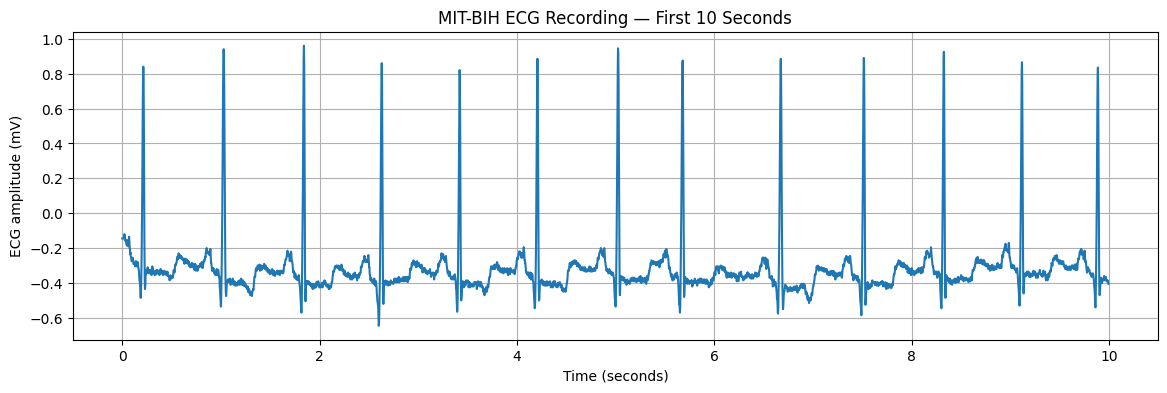

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(time[:sampling_rate * 10], signal[:sampling_rate * 10])
plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude (mV)")
plt.title("MIT-BIH ECG Recording — First 10 Seconds")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

RECORDS = [
    "100", "101", "102", "103", "104", "105", "106", "107",
    "108", "109", "111", "112", "113", "114", "115", "116",
    "117", "118", "119", "121", "122", "123", "124", "200",
    "201", "202", "203", "205", "207", "208", "209", "210",
    "212", "213", "214", "215", "217", "219", "220", "221",
    "222", "223", "228", "230", "231", "232", "233", "234"
]

# Binary beat labels for this project:
# 0 = normal beat; 1 = selected abnormal beat types.
# Paced beats (/) and fusion-of-paced-and-normal beats (f), as well as
# unclassifiable beats (Q), are deliberately excluded rather than labeled abnormal.
NORMAL_SYMBOLS = {"N", "L", "R", "e", "j"}
ABNORMAL_SYMBOLS = {"A", "a", "J", "S", "V", "E", "F"}

print("Normal annotation symbols:", sorted(NORMAL_SYMBOLS))
print("Abnormal annotation symbols:", sorted(ABNORMAL_SYMBOLS))
print("Excluded annotation symbols include: /, f, Q, +, ~, |, and other unsupported symbols")


Normal annotation symbols: ['L', 'N', 'R', 'e', 'j']
Abnormal annotation symbols: ['A', 'E', 'F', 'J', 'S', 'V', 'a']
Excluded annotation symbols include: /, f, Q, +, ~, |, and other unsupported symbols


In [ ]:
PRE_SAMPLES = int(0.2 * 360)
POST_SAMPLES = int(0.4 * 360)
INPUT_LENGTH = PRE_SAMPLES + POST_SAMPLES

In [ ]:
def extract_beats(record_name):
    """Extract fixed-length ECG beats and binary labels from one MIT-BIH record.

    Labels: 0 = normal (N/L/R/e/j); 1 = selected abnormal types (A/a/J/S/V/E/F).
    Other annotation symbols are ignored, not automatically treated as abnormal.
    """
    record_path = str(DATA_DIR / record_name)
    record = wfdb.rdrecord(record_path)
    annotation = wfdb.rdann(record_path, "atr")

    signal = record.p_signal[:, 0]
    fs = record.fs

    pre = int(0.2 * fs)
    post = int(0.4 * fs)

    beats = []
    labels = []

    for sample, symbol in zip(annotation.sample, annotation.symbol):
        if symbol in NORMAL_SYMBOLS:
            label = 0
        elif symbol in ABNORMAL_SYMBOLS:
            label = 1
        else:
            continue  # Do not classify unsupported / paced / unclassifiable symbols as abnormal.

        start = sample - pre
        end = sample + post
        if start < 0 or end > len(signal):
            continue  # Exclude beats whose windows cross the signal boundary.

        beat = signal[start:end].astype(np.float32)
        beat = (beat - beat.mean()) / (beat.std() + 1e-8)
        beats.append(beat)
        labels.append(label)

    return beats, labels


In [ ]:
from collections import Counter

record_name = "100"
record_path = str(DATA_DIR / record_name)
record = wfdb.rdrecord(record_path)
annotation = wfdb.rdann(record_path, "atr")

symbol_counts = Counter(annotation.symbol)
print(f"Annotation symbol counts for record {record_name}:")
for symbol, count in sorted(symbol_counts.items()):
    print(f"  {symbol!r}: {count}")

recognized_count = sum(
    symbol in NORMAL_SYMBOLS or symbol in ABNORMAL_SYMBOLS
    for symbol in annotation.symbol
)
beats, labels = extract_beats(record_name)
print("\nRecognized annotations before boundary filtering:", recognized_count)
print("Beats retained after boundary filtering:", len(labels))
print("Normal beats retained (label 0):", labels.count(0))
print("Abnormal beats retained (label 1):", labels.count(1))
print("Recognized beats excluded by boundary filtering:", recognized_count - len(labels))
print("Unsupported annotation symbols are excluded, not counted as abnormal.")


Annotation symbol counts for record 100:
  '+': 1
  'A': 33
  'N': 2239
  'V': 1

Recognized annotations before boundary filtering: 2273
Beats retained after boundary filtering: 2272
Normal beats retained (label 0): 2238
Abnormal beats retained (label 1): 34
Recognized beats excluded by boundary filtering: 1
Unsupported annotation symbols are excluded, not counted as abnormal.


In [ ]:
record_groups = [
    "201_202" if record in {"201", "202"} else record
    for record in RECORDS
]

indices = np.arange(len(RECORDS))

split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)

train_idx, remaining_idx = next(
    split1.split(indices, groups=record_groups)
)

remaining_records = [RECORDS[i] for i in remaining_idx]
remaining_groups = [record_groups[i] for i in remaining_idx]

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)

val_rel, test_rel = next(
    split2.split(remaining_records, groups=remaining_groups)
)

In [ ]:
train_records = [RECORDS[i] for i in train_idx]
val_records = [remaining_records[i] for i in val_rel]
test_records = [remaining_records[i] for i in test_rel]

In [ ]:
print("Training records:", len(train_records))
print("Validation records:", len(val_records))
print("Testing records:", len(test_records))

Training records: 32
Validation records: 8
Testing records: 8


In [ ]:
def build_dataset(record_list):
    """Build arrays from selected annotation types and report each record's labels."""
    X, y = [], []

    for record_name in record_list:
        beats, labels = extract_beats(record_name)
        X.extend(beats)
        y.extend(labels)

        normal_count = labels.count(0)
        abnormal_count = labels.count(1)
        print(
            f"{record_name} | Total retained beats: {len(labels)} "
            f"| Normal (0): {normal_count} "
            f"| Abnormal (1): {abnormal_count}"
        )

    if not X:
        raise ValueError(
            "No beats were extracted. Check DATA_DIR, the MIT-BIH files, and annotation symbols."
        )

    X_array = np.asarray(X, dtype=np.float32)
    y_array = np.asarray(y, dtype=np.int64)
    print("\nDataset shape:", X_array.shape)
    print("Overall label counts:", dict(zip(*np.unique(y_array, return_counts=True))))
    return X_array, y_array


In [ ]:
print("DATA_DIR:", DATA_DIR)
print("Record 100 exists:", (DATA_DIR / "100.hea").exists())
print("Record 100 data exists:", (DATA_DIR / "100.dat").exists())
print("Record 100 annotations exist:", (DATA_DIR / "100.atr").exists())

DATA_DIR: /content/data/mitdb
Record 100 exists: True
Record 100 data exists: True
Record 100 annotations exist: True


In [ ]:
X_train, y_train = build_dataset(train_records)
X_val, y_val = build_dataset(val_records)
X_test, y_test = build_dataset(test_records)

100 | Total retained beats: 2272 | Normal (0): 2238 | Abnormal (1): 34
101 | Total retained beats: 1863 | Normal (0): 1860 | Abnormal (1): 3
102 | Total retained beats: 103 | Normal (0): 99 | Abnormal (1): 4
105 | Total retained beats: 2567 | Normal (0): 2526 | Abnormal (1): 41
107 | Total retained beats: 59 | Normal (0): 0 | Abnormal (1): 59
109 | Total retained beats: 2531 | Normal (0): 2491 | Abnormal (1): 40
111 | Total retained beats: 2124 | Normal (0): 2123 | Abnormal (1): 1
112 | Total retained beats: 2538 | Normal (0): 2536 | Abnormal (1): 2
114 | Total retained beats: 1879 | Normal (0): 1820 | Abnormal (1): 59
115 | Total retained beats: 1952 | Normal (0): 1952 | Abnormal (1): 0
116 | Total retained beats: 2411 | Normal (0): 2301 | Abnormal (1): 110
117 | Total retained beats: 1534 | Normal (0): 1533 | Abnormal (1): 1
118 | Total retained beats: 2277 | Normal (0): 2165 | Abnormal (1): 112
119 | Total retained beats: 1987 | Normal (0): 1543 | Abnormal (1): 444
122 | Total retai

In [ ]:
from pathlib import Path
import wfdb

DATA_DIR = Path("/content/data/mitdb")

# Check the existing dataset
print("Dataset exists:", DATA_DIR.exists())
print("Record 100 exists:", (DATA_DIR / "100.hea").exists())

# Load record 100 and its annotations
record = wfdb.rdrecord(str(DATA_DIR / "100"))
annotation = wfdb.rdann(str(DATA_DIR / "100"), "atr")

print("\nRecord 100 sampling rate:", record.fs)
print("Total annotations:", len(annotation.symbol))
print("First 30 annotation symbols:", annotation.symbol[:30])
print("Unique annotation symbols:", sorted(set(annotation.symbol)))

Dataset exists: True
Record 100 exists: True

Record 100 sampling rate: 360
Total annotations: 2274
First 30 annotation symbols: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']
Unique annotation symbols: ['+', 'A', 'N', 'V']


In [ ]:
from collections import Counter

symbol_counts = Counter(annotation.symbol)

print("Annotation counts for record 100:")
for symbol, count in sorted(symbol_counts.items()):
    print(f"{symbol}: {count}")

# Count only the heartbeat symbols used in this project
BEAT_SYMBOLS = {"N", "A", "V"}

total_beats = sum(symbol_counts[s] for s in BEAT_SYMBOLS)
abnormal_beats = sum(symbol_counts[s] for s in {"A", "V"})

print("\nTotal heartbeat annotations:", total_beats)
print("Abnormal heartbeat annotations:", abnormal_beats)
print("Normal heartbeat annotations:", symbol_counts["N"])

Annotation counts for record 100:
+: 1
A: 33
N: 2239
V: 1

Total heartbeat annotations: 2273
Abnormal heartbeat annotations: 34
Normal heartbeat annotations: 2239


In [ ]:
print("\nShapes:")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Shapes:
Train: (69067, 216) (69067,)
Validation: (16941, 216) (16941,)
Test: (15410, 216) (15410,)


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    if "100.hea" in files:
        print("Dataset folder:", root)
        break

Dataset folder: /content/data/mitdb


In [ ]:
from collections import Counter

for record_name in ["100", "102", "107", "104", "217"]:
    record_path = str(DATA_DIR / record_name)
    ann = wfdb.rdann(record_path, "atr")
    counts = Counter(ann.symbol)
    recognized_normal = sum(count for symbol, count in counts.items() if symbol in NORMAL_SYMBOLS)
    recognized_abnormal = sum(count for symbol, count in counts.items() if symbol in ABNORMAL_SYMBOLS)
    ignored = sum(count for symbol, count in counts.items()
                  if symbol not in NORMAL_SYMBOLS and symbol not in ABNORMAL_SYMBOLS)
    print(f"Record {record_name}: normal-symbol annotations={recognized_normal}, "
          f"abnormal-symbol annotations={recognized_abnormal}, ignored annotations={ignored}")


Record 100: normal-symbol annotations=2239, abnormal-symbol annotations=34, ignored annotations=1
Record 102: normal-symbol annotations=99, abnormal-symbol annotations=4, ignored annotations=2089
Record 107: normal-symbol annotations=0, abnormal-symbol annotations=59, ignored annotations=2081
Record 104: normal-symbol annotations=163, abnormal-symbol annotations=2, ignored annotations=2146
Record 217: normal-symbol annotations=244, abnormal-symbol annotations=162, ignored annotations=1874


In [ ]:
%pip install torch torchvision torchaudio

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
def make_loader(X, y, shuffle=False):
    X_tensor = torch.tensor(X).unsqueeze(1)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    dataset = TensorDataset(X_tensor, y_tensor)

    return DataLoader(
        dataset,
        batch_size=128,
        shuffle=shuffle
    )

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

In [ ]:
import torch.nn as nn

In [ ]:
class ECG_CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)

In [ ]:
model = ECG_CNN().to(device)

In [ ]:
print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

ECG_CNN(
  (features): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 9217


In [ ]:
import copy

In [ ]:
normal_count = max(int((y_train == 0).sum()), 1)
abnormal_count = max(int((y_train == 1).sum()), 1)

In [ ]:
pos_weight = torch.tensor(
    [normal_count / abnormal_count],
    dtype=torch.float32,
    device=device
)

In [ ]:
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
EPOCHS = 30
PATIENCE = 5

In [ ]:
best_val_loss = float("inf")
best_state = None
patience_counter = 0

In [ ]:
history = {"train_loss": [], "val_loss": []}

In [ ]:
def evaluate_loss(loader):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            total_loss += loss.item() * len(y_batch)
            total_samples += len(y_batch)

    return total_loss / max(total_samples, 1)

In [ ]:
for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y_batch)
        total_samples += len(y_batch)

    train_loss = total_loss / max(total_samples, 1)
    val_loss = evaluate_loss(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping.")
        break

model.load_state_dict(best_state)

Epoch 01/30 | Train Loss: 0.6143 | Validation Loss: 0.9725
Epoch 02/30 | Train Loss: 0.4356 | Validation Loss: 1.0611
Epoch 03/30 | Train Loss: 0.3901 | Validation Loss: 1.3554
Epoch 04/30 | Train Loss: 0.3572 | Validation Loss: 0.9614
Epoch 05/30 | Train Loss: 0.3353 | Validation Loss: 1.5793
Epoch 06/30 | Train Loss: 0.3196 | Validation Loss: 1.1382
Epoch 07/30 | Train Loss: 0.3004 | Validation Loss: 1.3523
Epoch 08/30 | Train Loss: 0.2852 | Validation Loss: 1.0796
Epoch 09/30 | Train Loss: 0.2796 | Validation Loss: 1.2945
Early stopping.


<All keys matched successfully>

In [ ]:
plt.figure(figsize=(9, 4))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Weighted BCE Loss")
plt.title("ECG CNN Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

model.eval()

In [ ]:
all_probabilities = []
all_labels = []

In [ ]:
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        logits = model(X_batch)
        probabilities = torch.sigmoid(logits)

        all_probabilities.extend(probabilities.cpu().numpy())
        all_labels.extend(y_batch.numpy())

In [ ]:
y_true = np.asarray(all_labels, dtype=int)
y_prob = np.asarray(all_probabilities)
y_pred = (y_prob >= 0.5).astype(int)

In [ ]:
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Abnormal"],
    zero_division=0
))

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Abnormal"]
).plot()

plt.title("ECG Classification — Held-Out Recordings")
plt.show()

if len(np.unique(y_true)) == 2:
    print("ROC-AUC:", roc_auc_score(y_true, y_prob))
else:
    print("ROC-AUC unavailable: test set contains only one class.")

In [ ]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_length": INPUT_LENGTH,
        "sampling_rate": 360,
        "class_names": {
            0: "Normal",
            1: "Abnormal"
        },
        "threshold": 0.5
    },
    "cardiosignal_cnn.pth"
)

print("Model saved: cardiosignal_cnn.pth")